In [1]:
# Imports
import torch
from torchvision import transforms

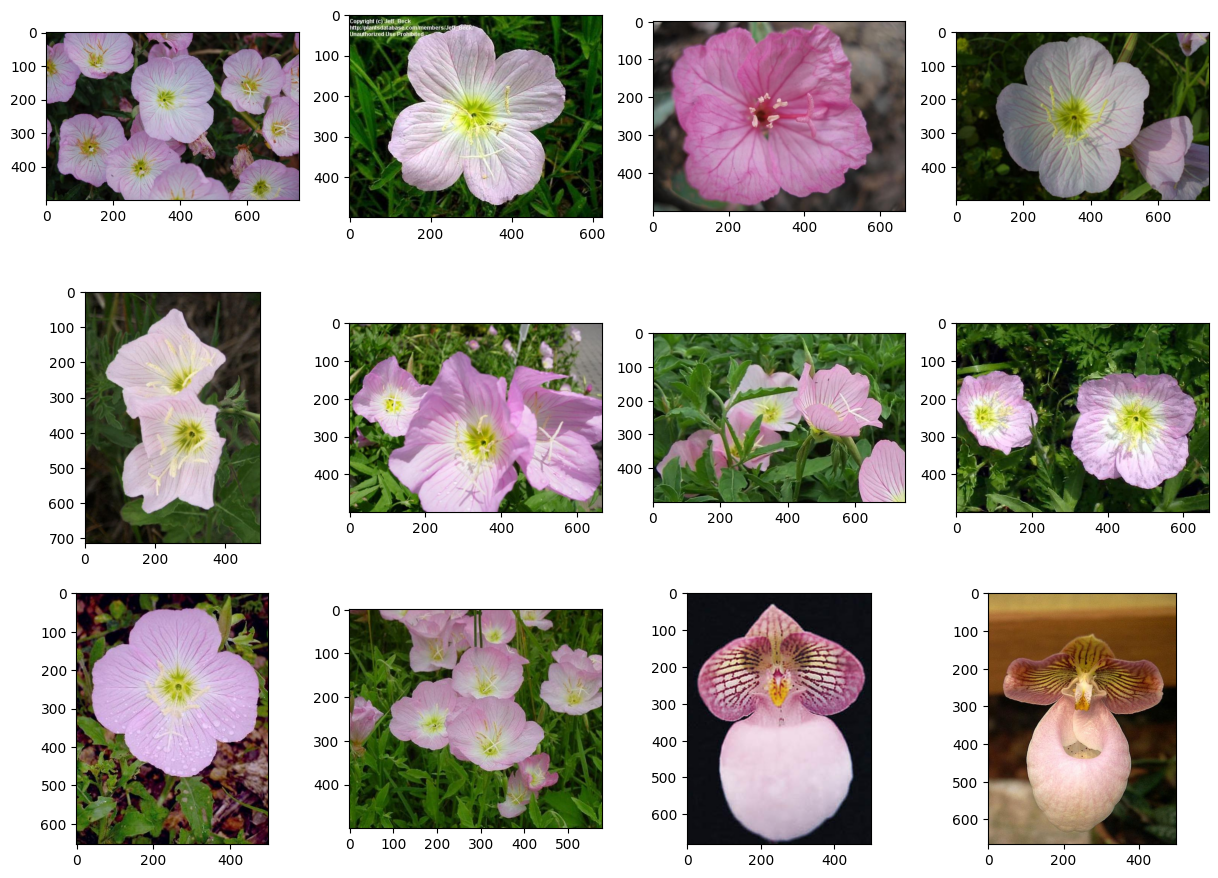

In [2]:
## Exploring the dataset
import torchvision
from matplotlib import pyplot as plt

def show_image(dataset, n=12, cols=4):
    """Plots some sample from the dataset"""
    plt.figure(figsize=(15,15))
    for i, img in enumerate(dataset):
        if i == n:
            break
        plt.subplot(int(n/cols)+1, cols, i+1)
        plt.imshow(img[0])
        
train_dataset = torchvision.datasets.Flowers102(root=".", download=True)
show_image(train_dataset)

In [3]:
## Create dataloaders
from torch.utils.data import DataLoader

IMG_SIZE = 64
BATCH_SIZE = 128

# Define the transformations
data_transforms = [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Lambda(lambda t: (t*2)-1)
]
data_transform = transforms.Compose(data_transforms)

train_dataset = torchvision.datasets.Flowers102(root=".", download=True, transform=data_transform, split='train')
test_dataset = torchvision.datasets.Flowers102(root=".", download=True, transform=data_transform, split='test')

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [4]:
import numpy as np
def show_tensor_image(image):
    reverse_transforms = transforms.Compose([
        transforms.Lambda(lambda t: (t + 1) / 2),
        transforms.Lambda(lambda t: t.permute(1, 2, 0)), # CHW to HWC
        transforms.Lambda(lambda t: t * 255.),
        transforms.Lambda(lambda t: t.numpy().astype(np.uint8)),
        transforms.ToPILImage(),
    ])
    
    # Take first image of batch
    if len(image.shape) == 4:
        image = image[0, :, :, :] 
    plt.imshow(reverse_transforms(image))

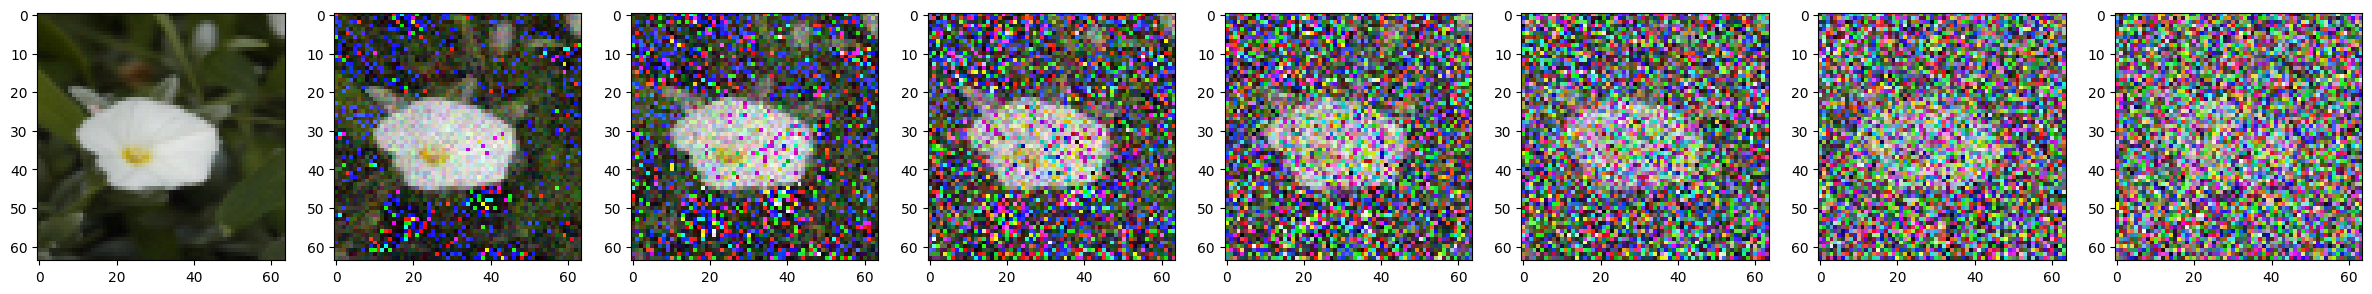

In [5]:
# Run forward diffusion process on a single image
from diffusion_forward import DiffusionForward

NUM_DIFFUSION_STEPS = 1000
BETA_START = 1e-4
BETA_END = 0.001

diffusion_forward = DiffusionForward(schedule_type="linear", num_timesteps=NUM_DIFFUSION_STEPS, beta_start=BETA_START, beta_end=BETA_END)

# Get a a single image from the dataloader
images, labels = next(iter(train_dataloader))

sample_image = images[BATCH_SIZE//2]

plt.figure(figsize=(30,20))
num_images = 8
stepsize = int(NUM_DIFFUSION_STEPS/num_images)

for idx in range(0, NUM_DIFFUSION_STEPS, stepsize):

    t = torch.Tensor([idx]).type(torch.int64)

    plt.subplot(2, num_images, int(idx/stepsize) + 1)

    # Generate a noise sample from normal distribution
    noise = torch.randn_like(sample_image) 

    # Generate the noised image at step t
    noisy_img = diffusion_forward.generate_noised_data(sample_image, t, noise)
    show_tensor_image(noisy_img)


In [6]:
# Create a Diffusion U-Net model
from diff_unet import DiffUNet

model = DiffUNet(in_channels=3, out_channels=3)
model.eval()

DiffUNet(
  (time_embedding): SinusoidalPositionalEmbedding()
  (down1): Downsample(
    (double_conv): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (embedding_proj): Linear(in_features=128, out_features=64, bias=True)
  )
  (down2): Downsample(
    (double_conv): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (embedding_proj): Linear(in_features=128, out_fe

In [9]:
# Load a sample data batch and run a forward pass through the model
images, labels = next(iter(train_dataloader))

t = torch.Tensor([0]).repeat(images.size(0)).type(torch.int64) # timestep 0 (no noise)

with torch.no_grad():
    output = model(images, t)

print("Output shape:", output.shape)

Output shape: torch.Size([128, 3, 64, 64])


## Train the Diffusion Model

In [10]:
# Set up the device and move the model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Set up the optimizer
import torch.optim as optim
optimizer = optim.Adam(model.parameters(), lr=1e-4)

/home/savio/anaconda3/envs/gen_modeling/lib/python3.11/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [11]:
# Define the loss function that will be used to train the model. 
# Going to use the F.L1Loss, which is commonly used in diffusion models to measure the difference between the predicted noise and the actual noise added to the image at each timestep.


In [ ]:
## Set up the training loop
from tqdm import tqdm
from torch.nn import functional as F

NUM_EPOCHS = 10

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss = 0.0
    for images, labels in tqdm(train_dataloader):
        images = images.to(device)
        
        # Sample random timesteps for each image in the batch
        t = torch.randint(0, NUM_DIFFUSION_STEPS, (images.size(0),)).type(torch.int64).to(device)
        
        # Generate random noise to add to the images
        noise = torch.randn_like(images).to(device)
        
        # Generate the noised images at the sampled timesteps
        noisy_images = diffusion_forward.generate_noised_data(images, t, noise)
        
        # Predict the noise using the model
        predicted_noise = model(noisy_images, t)
        
        # Compute the loss between the predicted noise and the actual noise
        loss = F.l1_loss(predicted_noise, noise)
        
        # Backpropagation and optimization step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
    
    avg_train_loss = train_loss / len(train_dataloader.dataset)
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}], Loss: {avg_train_loss:.4f}")